# Analysis of results of HOpt experiments

In these experiments the seeds of hyperparemeter optimisation algorithms are varied and the seeds of train pipeline are always fixed.
In this way the hyperparameter optimisation as source of variance is examined.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pathlib
import scipy.stats

import isml_data_analysis.data
import isml_data_analysis.visualization

In [3]:
PATH_DATA = pathlib.Path("../data")
PATH_DATA_RAW = PATH_DATA / "raw"

## Experiments and their metadata

In [4]:
experiments = [
    {
        "path": PATH_DATA_RAW / "8_tpe_opt_seeds_impure_full_seeds",
        "algorithm": "tpe.suggest",
        "dataset": "coins",
        "metric": "error rate"
    },
    {
        "path": PATH_DATA_RAW / '9_tpe_opt_seeds_impure_full_random_seeds',
        "algorithm": "tpe.suggest",
        "dataset": "coins",
        "metric": "error rate"
    },
    {
        "path": PATH_DATA_RAW / '4_tpe_suggest_optimal_hp_AdamW_seeds',
        "algorithm": "tpe.suggest",
        "dataset": "simpsons",
        "metric": "error rate"
    },
    {
        "path": PATH_DATA_RAW / '11_coins_hopt_tpe_impure_full_random_seeds',
        "algorithm": "tpe.suggest",
        "dataset": "coins",
        "metric": "error rate"
    },
    {
        "path": PATH_DATA_RAW / '12_coins_hopt_tpe_impure_full_random_seeds_1000',
        "algorithm": "tpe.suggest",
        "dataset": "coins",
        "metric": "error rate"
    },
    {
        "path": PATH_DATA_RAW / '7_simpsons_hopt_tpe_AdamW_seeds_random',
        "algorithm": "tpe.suggest",
        "dataset": "simpsons",
        "metric": "error rate"
    }
]

In [5]:
FILE_NAME_RESULTS_FULL = "omniopt_results.csv"
FILE_NAME_RESULTS_MINIMA_ALL = "omniopt_results_min_all.csv"
FILE_NAME_RESULTS_MINIMA_LATEST = "omniopt_results_min_latest.csv"

## Read the data

In [6]:
def read_experiment_df(path: pathlib.Path, file: str) -> pd.DataFrame:
    print(f"Reading data from {path / file} ...")
    df = pd.read_csv(path / file)
    try:
        df.drop("omniopt_seed.1", axis=1, inplace=True)
    except Exception as e:
        print(e)
        print(
            f"This is a bug caused by results extraction script. Omniopt seed is in columns = {'omniopt_seed' in df.columns}.")
        pass
    return df


experiments_data = {
    experiment["path"].name: {
        FILE_NAME_RESULTS_FULL: read_experiment_df(experiment["path"], FILE_NAME_RESULTS_FULL),
        FILE_NAME_RESULTS_MINIMA_ALL: read_experiment_df(experiment["path"], FILE_NAME_RESULTS_MINIMA_ALL),
        FILE_NAME_RESULTS_MINIMA_LATEST: read_experiment_df(experiment["path"], FILE_NAME_RESULTS_MINIMA_LATEST),
    } for experiment in experiments
}

Reading data from ../data/raw/8_tpe_opt_seeds_impure_full_seeds/omniopt_results.csv ...
"['omniopt_seed.1'] not found in axis"
This is a bug caused by results extraction script. Omniopt seed is in columns = True.
Reading data from ../data/raw/8_tpe_opt_seeds_impure_full_seeds/omniopt_results_min_all.csv ...
Reading data from ../data/raw/8_tpe_opt_seeds_impure_full_seeds/omniopt_results_min_latest.csv ...
Reading data from ../data/raw/9_tpe_opt_seeds_impure_full_random_seeds/omniopt_results.csv ...
"['omniopt_seed.1'] not found in axis"
This is a bug caused by results extraction script. Omniopt seed is in columns = True.
Reading data from ../data/raw/9_tpe_opt_seeds_impure_full_random_seeds/omniopt_results_min_all.csv ...
Reading data from ../data/raw/9_tpe_opt_seeds_impure_full_random_seeds/omniopt_results_min_latest.csv ...
Reading data from ../data/raw/4_tpe_suggest_optimal_hp_AdamW_seeds/omniopt_results.csv ...
"['omniopt_seed.1'] not found in axis"
This is a bug caused by results e

## Examine optimisation paths

Accumulated min applied to each hopt path. Then the matrix is built where the row i is (acc. min) hopt path for seed i and column is state of the metric on this iteration. The min and max is then taken over columns to estimate the top and bottom border.

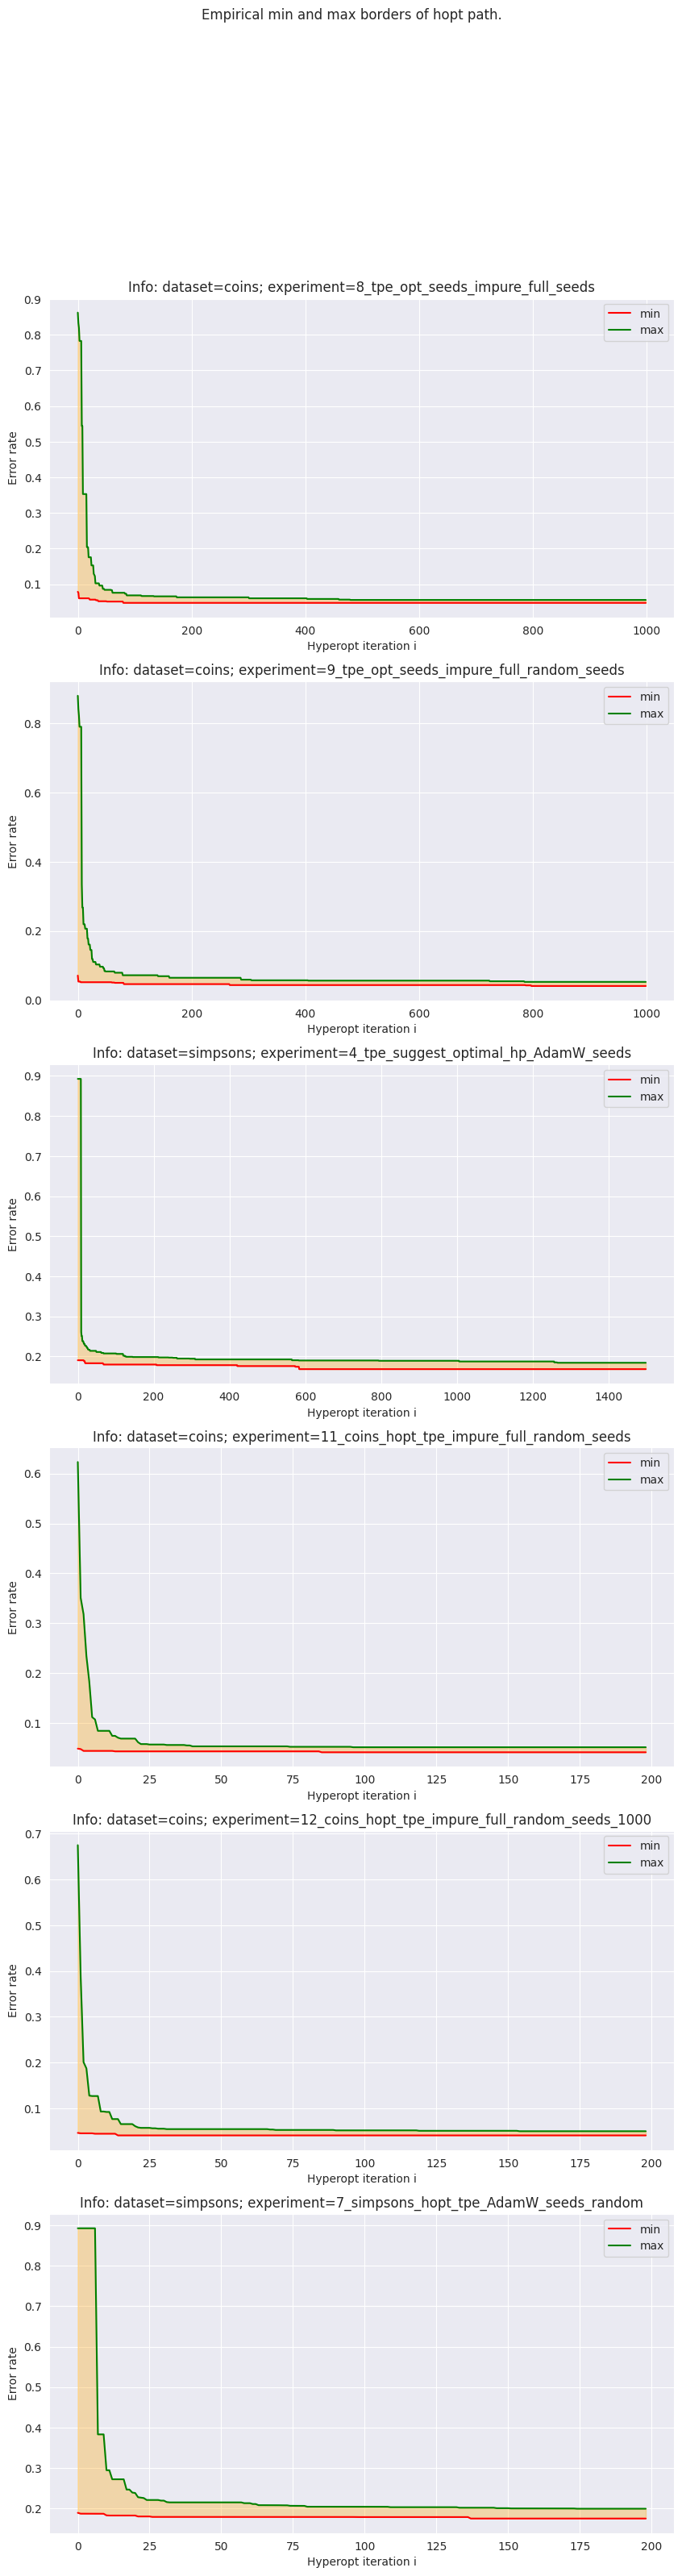

In [7]:
fig, axs = plt.subplots(nrows=len(experiments), figsize=(10, 6 * len(experiments)))
fig.suptitle("Empirical min and max borders of hopt path.")
for experiment, ax in zip(experiments, axs):
    isml_data_analysis.visualization.hopt_results_plot.plot_opt_iterations(
        df=experiments_data[experiment["path"].name][FILE_NAME_RESULTS_FULL],
        experiment_name=experiment["path"].name,
        dataset_name=experiment["dataset"],
        hopt_algorithm_name=experiment["algorithm"],
        metric_name=experiment["metric"],
        ax=ax,
        title_pre="Info"
    )

## Examine HOpt result metric distribution.

Examine the empirical distribution of metric values obtained from performing hopt with different hopt-algorithm seeds.
(One value of metric refers to minimum value obtained from hopt with given seed)

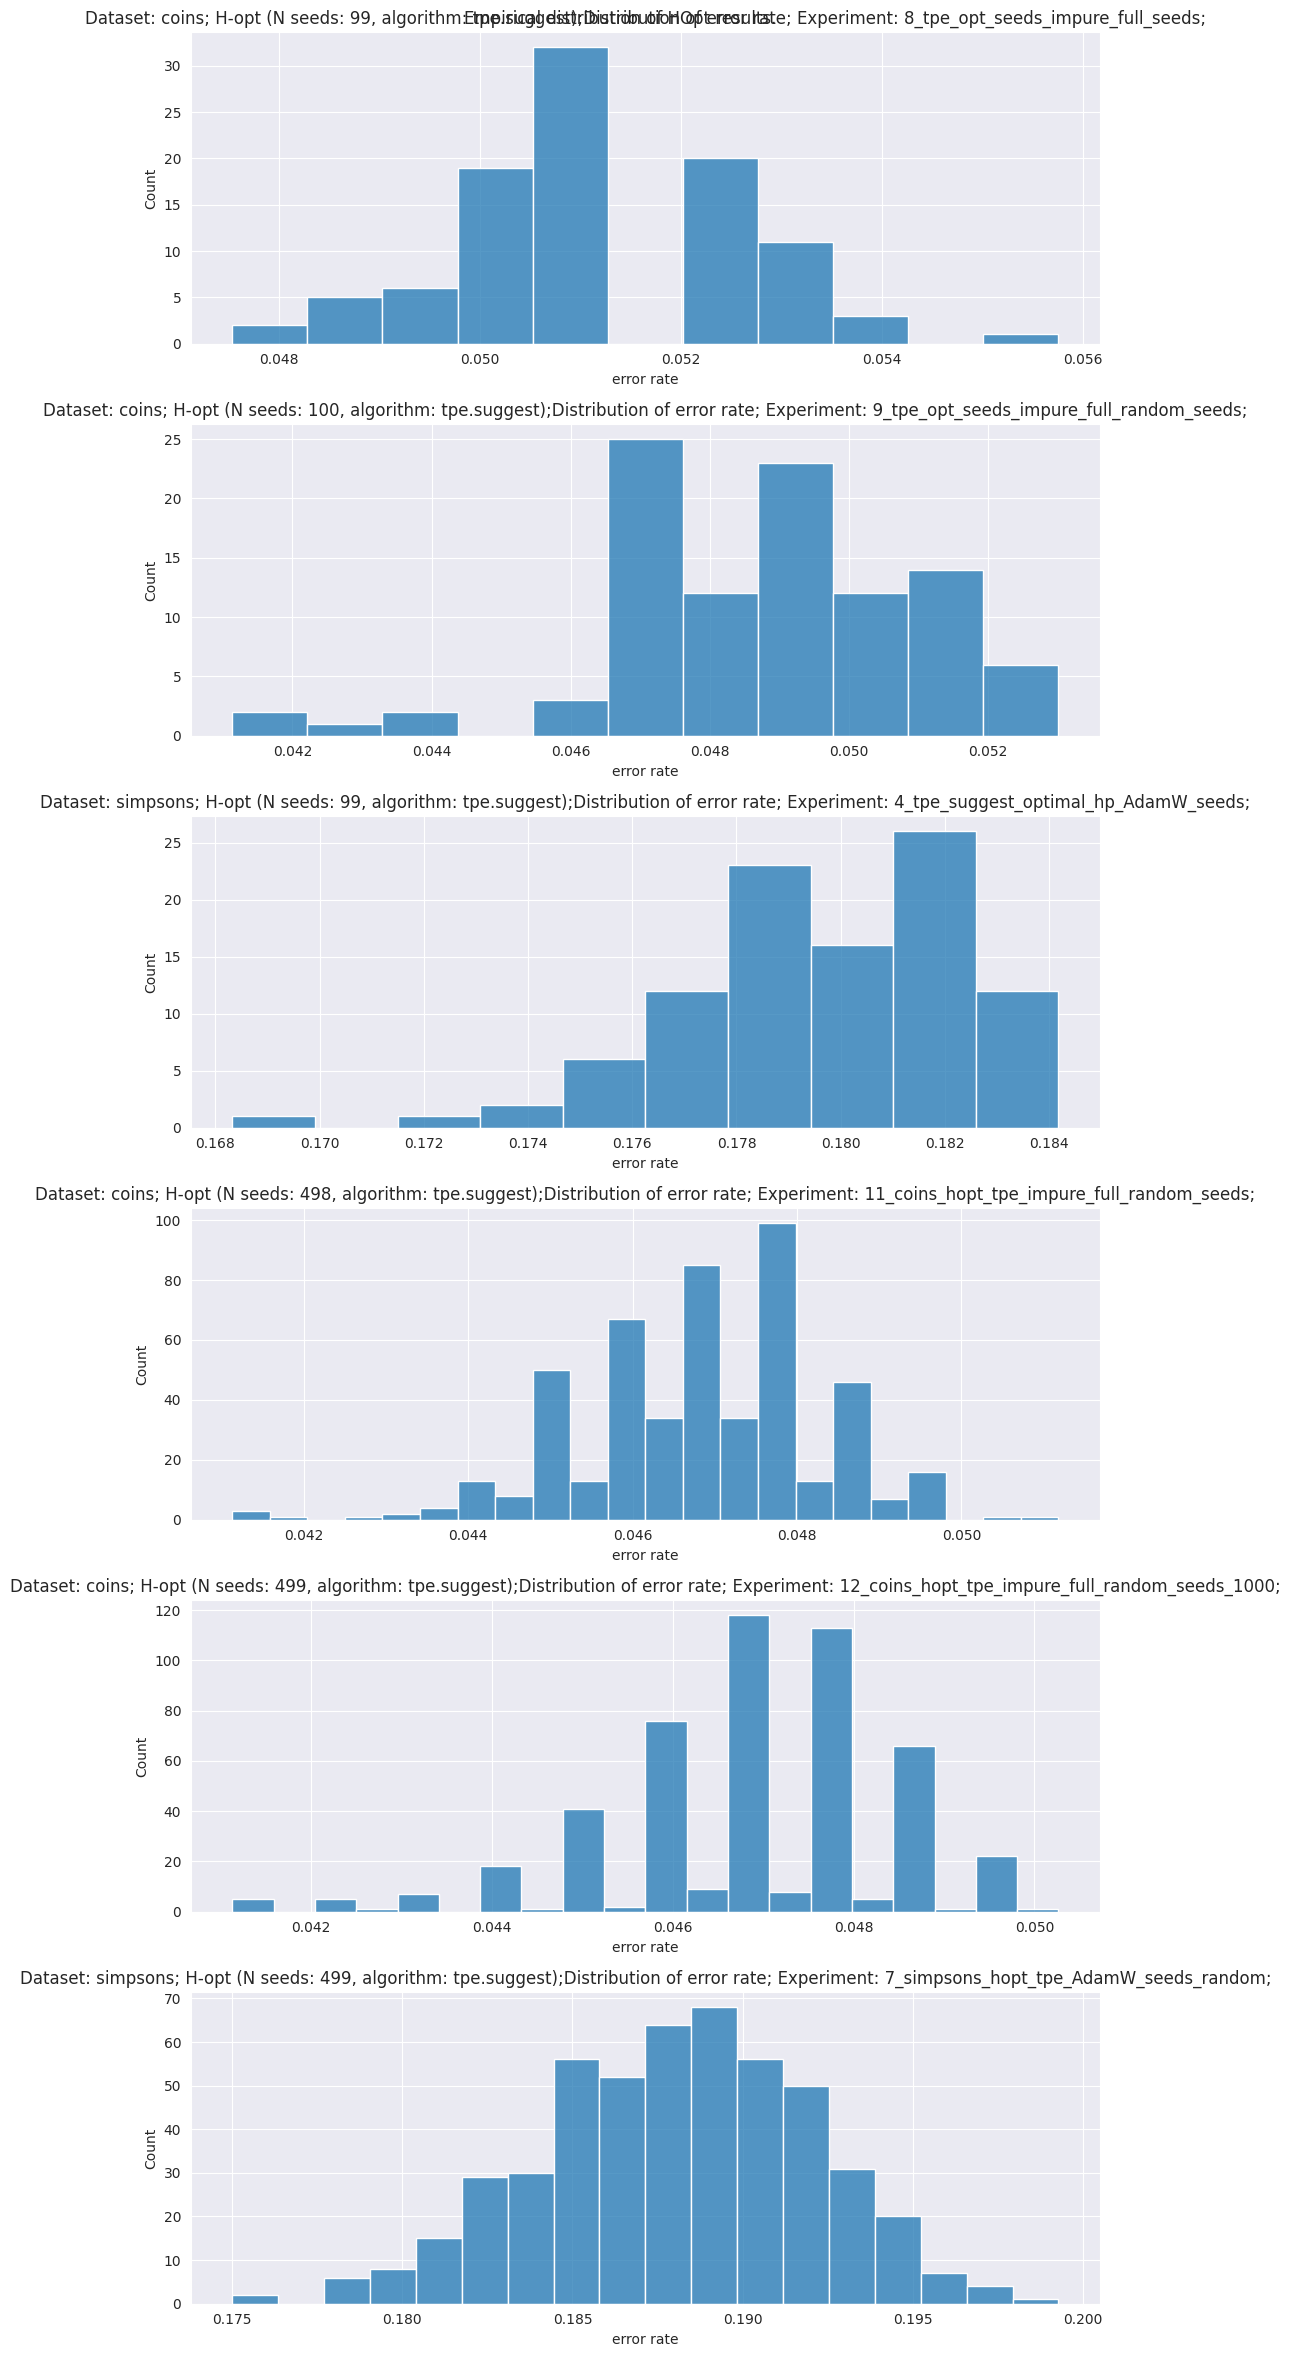

In [14]:
fig, axs = plt.subplots(nrows=len(experiments), figsize=(10, 4 * len(experiments)))
fig.suptitle("Empirical distribution of HOpt results.")
for experiment, ax in zip(experiments, axs):
    isml_data_analysis.visualization.hopt_results_plot.plot_metric_hist(
        df=experiments_data[experiment["path"].name][FILE_NAME_RESULTS_MINIMA_LATEST],
        experiment_name=experiment["path"].name,
        dataset_name=experiment["dataset"],
        hopt_algorithm_name=experiment["algorithm"],
        metric_name=experiment["metric"],
        ax=ax,
        bins='auto'
    )
fig.tight_layout()

### Test on normal distribution

In [13]:
for experiment in experiments:

    stat = scipy.stats.shapiro(
        experiments_data[experiment["path"].name][FILE_NAME_RESULTS_MINIMA_LATEST]["RESULT"]
    )
    print(experiment["path"].name, stat)

8_tpe_opt_seeds_impure_full_seeds ShapiroResult(statistic=0.9522367715835571, pvalue=0.0012493138201534748)
9_tpe_opt_seeds_impure_full_random_seeds ShapiroResult(statistic=0.9377506971359253, pvalue=0.00014094349171500653)
4_tpe_suggest_optimal_hp_AdamW_seeds ShapiroResult(statistic=0.9397379755973816, pvalue=0.00020091723126824945)
11_coins_hopt_tpe_impure_full_random_seeds ShapiroResult(statistic=0.9523181319236755, pvalue=1.3602612959628946e-11)
12_coins_hopt_tpe_impure_full_random_seeds_1000 ShapiroResult(statistic=0.9347221851348877, pvalue=5.8171370010459e-14)
7_simpsons_hopt_tpe_AdamW_seeds_random ShapiroResult(statistic=0.9955806136131287, pvalue=0.1713712215423584)


## Investigate hopt result metric dependency from seed

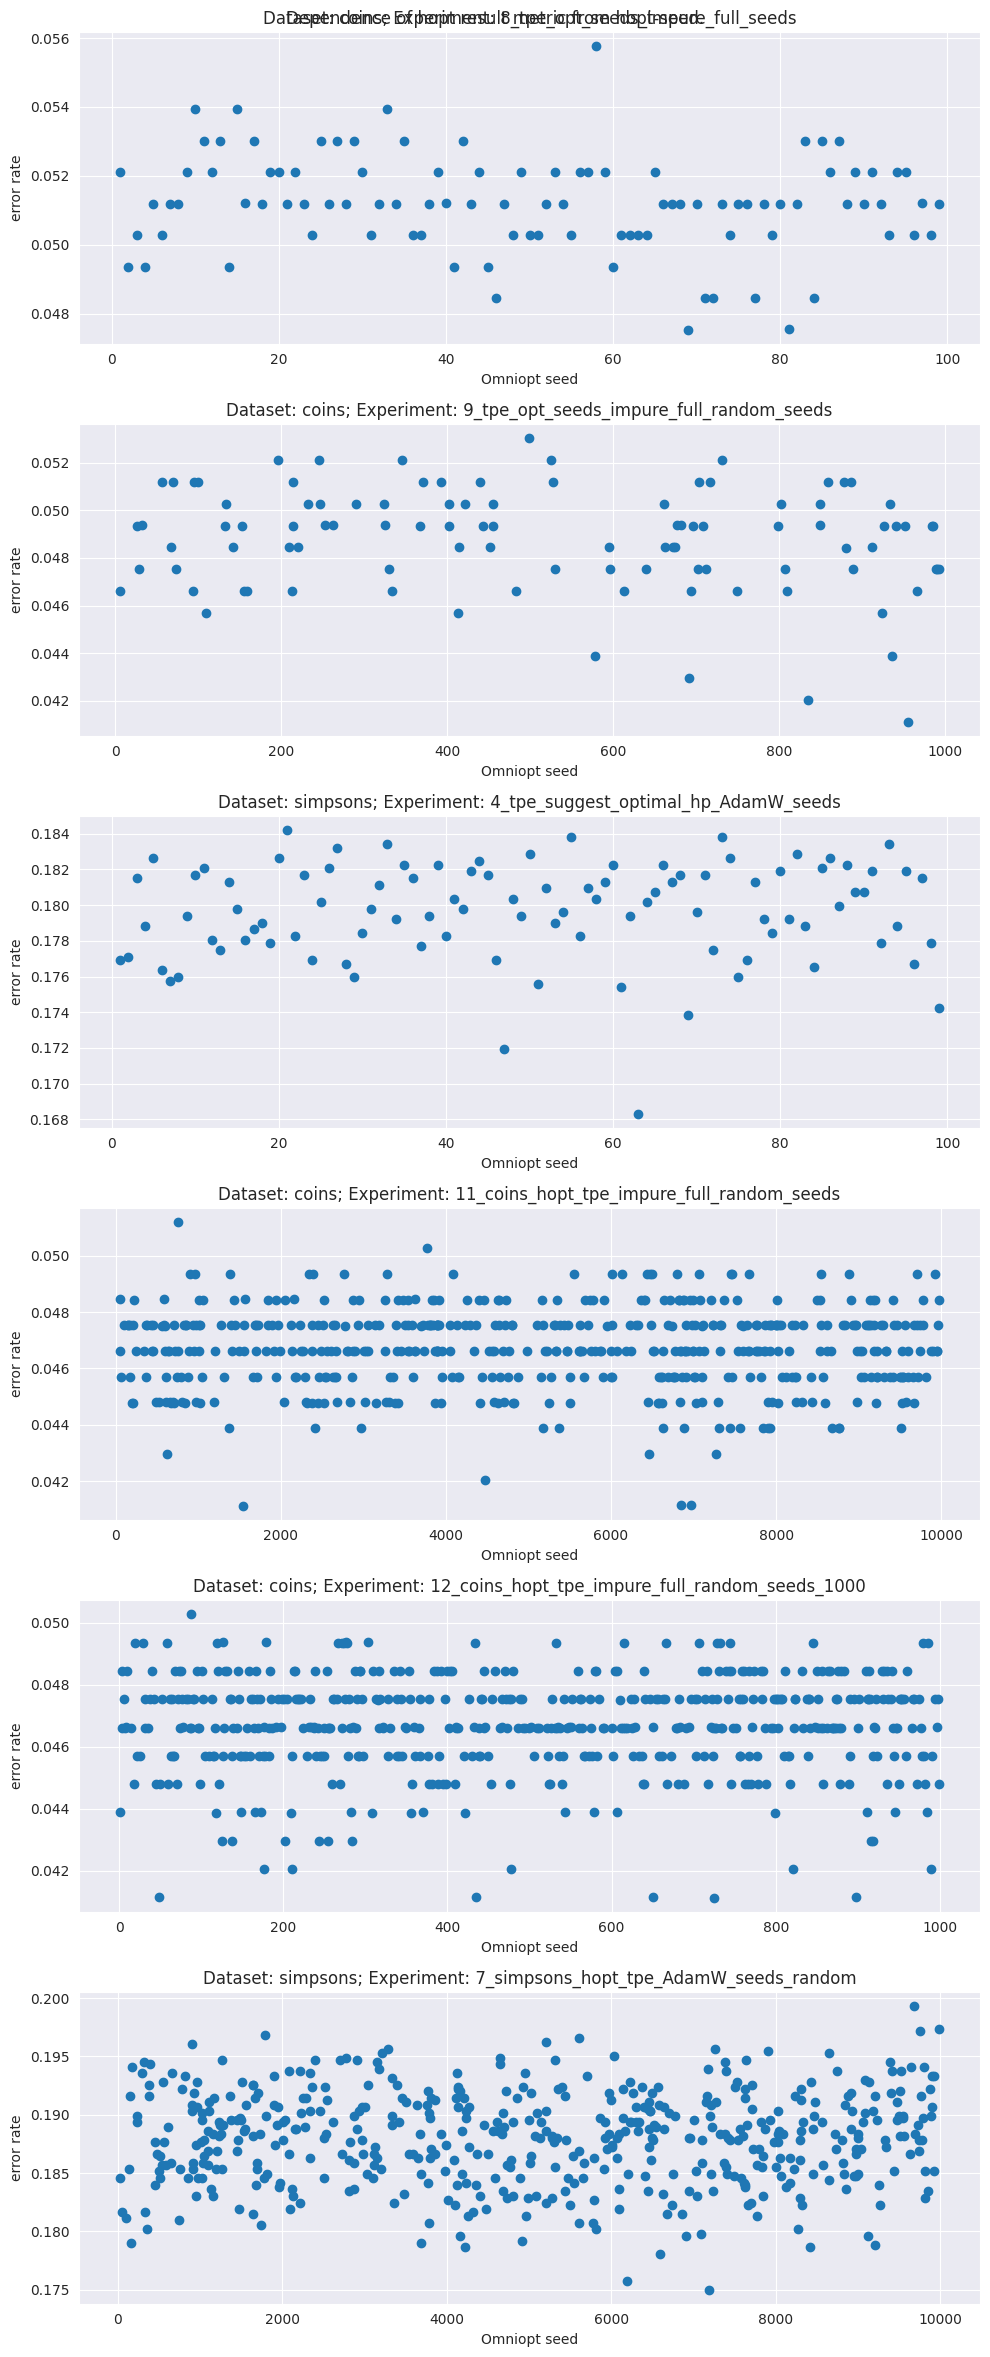

In [11]:
fig: plt.Figure
axs: list[plt.Axes]
fig, axs = plt.subplots(nrows=len(experiments), figsize=(10, 4 * len(experiments)))
fig.suptitle("Dependence of hopt result metric from hopt-seed.")
for experiment, ax in zip(experiments, axs):
    ax.scatter(
        x=experiments_data[experiment["path"].name][FILE_NAME_RESULTS_MINIMA_LATEST]["omniopt_seed"],
        y=experiments_data[experiment["path"].name][FILE_NAME_RESULTS_MINIMA_LATEST]["RESULT"]
    )
    ax.set_xlabel("Omniopt seed")
    ax.set_ylabel(f"{experiment['metric']}")
    ax.set_title(f"Dataset: {experiment['dataset']}; Experiment: {experiment['path'].name}")
fig.tight_layout()